# A/B Test Analysis: One-Page Checkout Redesign

**Question.** Did the redesigned checkout produce a statistically and commercially meaningful lift in revenue, without hurting refunds?

**Design (fixed before looking at outcomes; see `docs/experiment_design.md`)**

| Item | Choice |
|---|---|
| Unit / randomisation | User, 50/50, 14 days (2 Mar to 15 Mar 2026) |
| Primary metric | Conversion rate (purchase / user) |
| Secondary metrics | Revenue per visitor (RPV), average order value (AOV) |
| Guardrail | Refund rate among orders (non-inferiority margin +1.5 pts) |
| Error rates | alpha = 0.05 (two-sided), power = 80% |
| Minimum detectable effect | +8% relative on a 5.0% baseline |
| Segments (pre-registered, Holm-corrected) | device, new vs returning |

Aggregation is in SQL (`sql/experiment_queries.sql`); inference is done here.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportions_ztest, proportion_effectsize, confint_proportions_2indep
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")
ROOT = Path("..").resolve(); PROC, ASSETS, RESULTS = ROOT/"data/processed", ROOT/"assets", ROOT/"results"
ASSETS.mkdir(exist_ok=True); RESULTS.mkdir(exist_ok=True)
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8985"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10})
ALPHA, POWER, BASELINE, MDE_REL = 0.05, 0.80, 0.05, 0.08
rng = np.random.default_rng(42)
M = {}     # results written to results/ab_metrics.json

df = pd.read_csv(PROC/"exp_users.csv", parse_dates=["assigned_date"])
c, t = df[df.variant == "control"], df[df.variant == "treatment"]
print(df.shape, "| control", len(c), "| treatment", len(t))

(124000, 9) | control 61857 | treatment 62143


## 1. Sample-size and power check

Required users per arm to detect a relative lift of `MDE_REL` on the baseline with the stated alpha and power
(normal approximation via Cohen's h).

,80% power,90% power
MDE (users per arm),,
4% relative,189921,254251
6% relative,85182,114035
8% relative,48347,64724
10% relative,31217,41791
15% relative,14177,18979


Required per arm for +8% relative MDE at 80% power: 48,347; achieved: 61,857 / 62,143


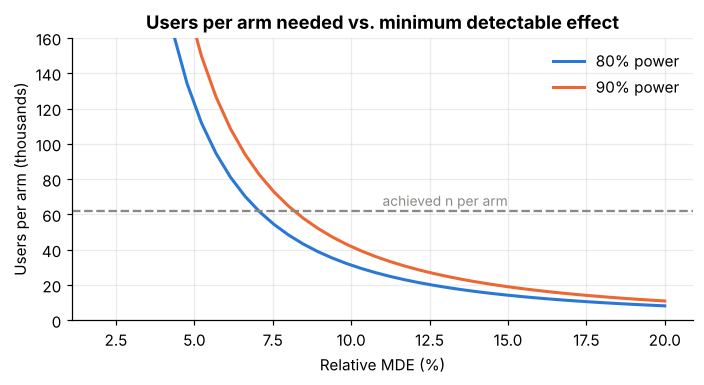

Guardrail: ~3,093 orders per arm; SE of refund-rate difference = 0.60 pts


,margin (pts),power to show non-inferiority
0,1.0,0.26
1,1.5,0.58
2,2.0,0.85


In [2]:
def n_required(p0, rel_mde, alpha=ALPHA, power=POWER):
    es = proportion_effectsize(p0 * (1 + rel_mde), p0)
    return NormalIndPower().solve_power(effect_size=es, alpha=alpha, power=power, ratio=1.0)

n_req = n_required(BASELINE, MDE_REL)
tab = pd.DataFrame({f"{int(pw*100)}% power": [round(n_required(BASELINE, m, power=pw)) for m in (0.04, 0.06, 0.08, 0.10, 0.15)]
                    for pw in (0.8, 0.9)}, index=[f"{int(m*100)}% relative" for m in (0.04, 0.06, 0.08, 0.10, 0.15)])
tab.index.name = "MDE (users per arm)"
display(tab)
print(f"Required per arm for +8% relative MDE at 80% power: {n_req:,.0f}; achieved: {len(c):,} / {len(t):,}")

grid = np.linspace(0.02, 0.20, 40)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for pw, col in ((0.8, BLUE), (0.9, ORANGE)):
    ax.plot(grid*100, [n_required(BASELINE, m, power=pw)/1e3 for m in grid], color=col, lw=2, label=f"{int(pw*100)}% power")
ax.axhline(len(c)/1e3, color=GREY, ls="--"); ax.text(11, len(c)/1e3 + 3, "achieved n per arm", color=GREY, fontsize=9)
ax.set(title="Users per arm needed vs. minimum detectable effect", xlabel="Relative MDE (%)", ylabel="Users per arm (thousands)"); ax.legend(frameon=False); ax.set_ylim(0, 160)
plt.tight_layout(); plt.savefig(ASSETS/"01_power_curve.png", dpi=150, bbox_inches="tight"); plt.show()
# ---- guardrail power: can this test *demonstrate* non-inferiority at a given margin?
orders_per_arm = BASELINE * len(c); p_ref, true_diff = 0.06, 0.002        # refund rate 6%, assume a true +0.2 pt difference
se_ni = np.sqrt(2 * p_ref * (1 - p_ref) / orders_per_arm)
gp = pd.DataFrame({"margin (pts)": [1.0, 1.5, 2.0],
                   "power to show non-inferiority": [stats.norm.cdf((m - true_diff) / se_ni - 1.96) for m in (0.01, 0.015, 0.02)]}).round(2)
print(f"Guardrail: ~{orders_per_arm:,.0f} orders per arm; SE of refund-rate difference = {100*se_ni:.2f} pts"); display(gp)
M["power"] = dict(baseline=BASELINE, mde_rel=MDE_REL, n_required_per_arm=int(np.ceil(n_req)), n_control=len(c), n_treatment=len(t))

## 2. Trust checks before reading any result

**Sample ratio mismatch (SRM).** A 50/50 design should produce close to equal arms; a significant imbalance (p < 0.001 is the usual alarm)
signals a broken assignment or logging bug and invalidates the test. **Covariate balance** checks that randomisation produced comparable groups.

In [3]:
chi = stats.chisquare([len(c), len(t)], f_exp=[len(df)/2]*2)
print(f"SRM check: {len(c):,} vs {len(t):,}  chi2={chi.statistic:.2f}  p={chi.pvalue:.3f}  ->", "OK" if chi.pvalue > 0.001 else "ALARM")

bal = []
for col in ("device", "is_returning"):
    ct = pd.crosstab(df[col], df.variant); p = stats.chi2_contingency(ct)[1]
    bal.append((col, "chi-square", p))
p = stats.ttest_ind(c.pre_period_spend, t.pre_period_spend, equal_var=False).pvalue
bal.append(("pre_period_spend", "Welch t", p))
bal = pd.DataFrame(bal, columns=["covariate", "test", "p_value"]).round(3); display(bal)
M["srm_p"] = round(float(chi.pvalue), 3); M["balance_min_p"] = float(bal.p_value.min())

SRM check: 61,857 vs 62,143  chi2=0.66  p=0.417  -> OK


,covariate,test,p_value
0,device,chi-square,0.157
1,is_returning,chi-square,0.884
2,pre_period_spend,Welch t,0.798


## 3. Primary metric: conversion rate

Two-proportion z-test; Newcombe confidence interval for the absolute difference; log relative-risk interval for the relative lift.

control 5.139%  treatment 5.468%
absolute diff = +0.329 pts  (95% CI +0.079 to +0.578)   z = 2.58   p = 0.0098
relative lift = +6.4%  (95% CI +1.5% to +11.5%)


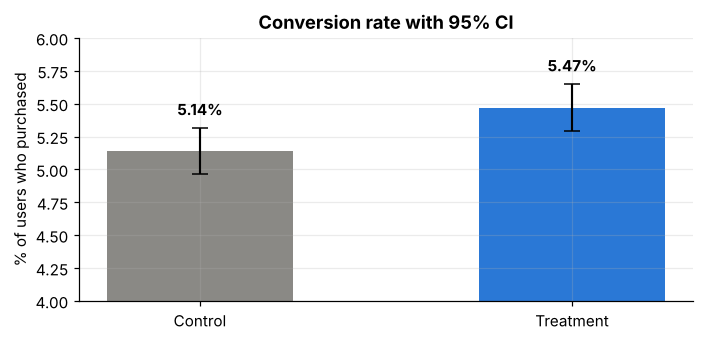

In [4]:
x = np.array([t.converted.sum(), c.converted.sum()]); n = np.array([len(t), len(c)])
p_t, p_c = x / n
z, p_val = proportions_ztest(x, n, alternative="two-sided")
lo, hi = confint_proportions_2indep(x[0], n[0], x[1], n[1], method="newcombe", compare="diff")
rr = p_t / p_c; se = np.sqrt((1-p_t)/x[0] + (1-p_c)/x[1])
rr_lo, rr_hi = np.exp(np.log(rr) - 1.96*se), np.exp(np.log(rr) + 1.96*se)
print(f"control {p_c:.3%}  treatment {p_t:.3%}")
print(f"absolute diff = {100*(p_t-p_c):+.3f} pts  (95% CI {100*lo:+.3f} to {100*hi:+.3f})   z = {z:.2f}   p = {p_val:.4f}")
print(f"relative lift = {100*(rr-1):+.1f}%  (95% CI {100*(rr_lo-1):+.1f}% to {100*(rr_hi-1):+.1f}%)")
M["conversion"] = dict(control=round(100*p_c, 3), treatment=round(100*p_t, 3), diff_pts=round(100*(p_t-p_c), 3),
    diff_ci=[round(100*lo, 3), round(100*hi, 3)], rel_lift_pct=round(100*(rr-1), 1),
    rel_ci=[round(100*(rr_lo-1), 1), round(100*(rr_hi-1), 1)], z=round(float(z), 2), p=float(p_val))

fig, ax = plt.subplots(figsize=(6.5, 3.2))
for i, (lab, p_, nn, col) in enumerate((("Control", p_c, n[1], GREY), ("Treatment", p_t, n[0], BLUE))):
    e = 1.96*np.sqrt(p_*(1-p_)/nn)
    ax.bar(lab, 100*p_, color=col, width=.5); ax.errorbar(lab, 100*p_, yerr=100*e, color="black", capsize=5, lw=1.4)
    ax.text(i, 100*(p_+e)+.1, f"{100*p_:.2f}%", ha="center", fontweight="bold")
ax.set(title="Conversion rate with 95% CI", ylabel="% of users who purchased"); ax.set_ylim(4, 6)
plt.tight_layout(); plt.savefig(ASSETS/"02_conversion_ci.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Secondary metrics: revenue per visitor and order value

Revenue is zero for ~95% of users and heavily right-skewed, so a t-test alone is fragile. We report Welch's t-test, a **nonparametric bootstrap** CI
(2,000 resamples of users) and a **CUPED** variance-reduced estimate that uses each user's pre-experiment spend as a covariate.

RPV control $4.850  treatment $5.426  diff $+0.576  (Welch p = 0.0002)
bootstrap 95% CI diff $+0.282 to $+0.881;  relative +11.9% (+5.7% to +18.7%)
CUPED: theta=0.105, correlation(pre, post)=0.172, variance reduction = 2.9%
CUPED diff $+0.582  (95% CI +0.285 to +0.879), p = 0.0001  vs. raw SE 0.1538 -> CUPED SE 0.1516
AOV (buyers) control $94.38  treatment $99.23  Welch p = 0.005  Mann-Whitney p = 0.008


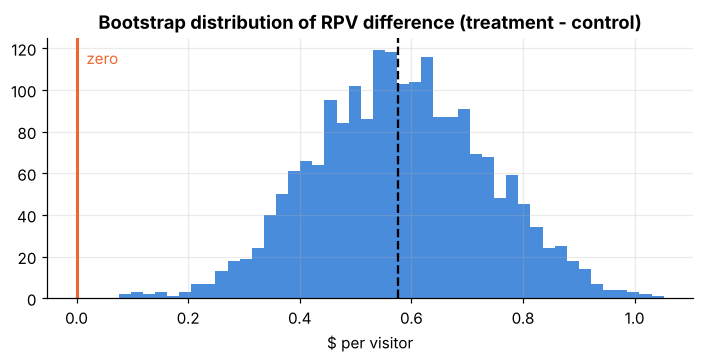

In [5]:
yt, yc = t.order_value.values, c.order_value.values
w = stats.ttest_ind(yt, yc, equal_var=False)
diff = yt.mean() - yc.mean()

B = 2000; d_boot = np.empty(B); r_boot = np.empty(B)
for b in range(B):
    mt = rng.choice(yt, len(yt)).mean(); mc = rng.choice(yc, len(yc)).mean()
    d_boot[b], r_boot[b] = mt - mc, mt / mc - 1
d_lo, d_hi = np.percentile(d_boot, [2.5, 97.5]); r_lo, r_hi = np.percentile(r_boot, [2.5, 97.5])
print(f"RPV control ${yc.mean():.3f}  treatment ${yt.mean():.3f}  diff ${diff:+.3f}  (Welch p = {w.pvalue:.4f})")
print(f"bootstrap 95% CI diff ${d_lo:+.3f} to ${d_hi:+.3f};  relative {100*(yt.mean()/yc.mean()-1):+.1f}% ({100*r_lo:+.1f}% to {100*r_hi:+.1f}%)")

# ---- CUPED
X = df.pre_period_spend.values; Y = df.order_value.values
theta = np.cov(Y, X)[0, 1] / np.var(X, ddof=1)
df["y_cuped"] = Y - theta * (X - X.mean())
ct_, cc_ = df[df.variant == "treatment"].y_cuped.values, df[df.variant == "control"].y_cuped.values
wc = stats.ttest_ind(ct_, cc_, equal_var=False)
diff_c = ct_.mean() - cc_.mean()
se_c = np.sqrt(ct_.var(ddof=1)/len(ct_) + cc_.var(ddof=1)/len(cc_)); se_raw = np.sqrt(yt.var(ddof=1)/len(yt) + yc.var(ddof=1)/len(yc))
var_red = 1 - (se_c/se_raw)**2
print(f"CUPED: theta={theta:.3f}, correlation(pre, post)={np.corrcoef(X, Y)[0,1]:.3f}, variance reduction = {100*var_red:.1f}%")
print(f"CUPED diff ${diff_c:+.3f}  (95% CI {diff_c-1.96*se_c:+.3f} to {diff_c+1.96*se_c:+.3f}), p = {wc.pvalue:.4f}  vs. raw SE {se_raw:.4f} -> CUPED SE {se_c:.4f}")

# ---- AOV among buyers
bt, bc = t[t.converted == 1].order_value, c[c.converted == 1].order_value
print(f"AOV (buyers) control ${bc.mean():.2f}  treatment ${bt.mean():.2f}  Welch p = {stats.ttest_ind(bt, bc, equal_var=False).pvalue:.3f}  Mann-Whitney p = {stats.mannwhitneyu(bt, bc).pvalue:.3f}")

M["rpv"] = dict(control=round(float(yc.mean()), 3), treatment=round(float(yt.mean()), 3), diff=round(float(diff), 3),
    rel_lift_pct=round(100*(yt.mean()/yc.mean()-1), 1), welch_p=float(w.pvalue), boot_ci=[round(float(d_lo), 3), round(float(d_hi), 3)],
    boot_rel_ci=[round(100*float(r_lo), 1), round(100*float(r_hi), 1)],
    cuped=dict(theta=round(float(theta), 3), corr=round(float(np.corrcoef(X, Y)[0, 1]), 3), variance_reduction_pct=round(100*float(var_red), 1),
               diff=round(float(diff_c), 3), ci=[round(float(diff_c-1.96*se_c), 3), round(float(diff_c+1.96*se_c), 3)], p=float(wc.pvalue)))
M["aov"] = dict(control=round(float(bc.mean()), 2), treatment=round(float(bt.mean()), 2), welch_p=float(stats.ttest_ind(bt, bc, equal_var=False).pvalue))

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.hist(d_boot, bins=45, color=BLUE, alpha=.85); ax.axvline(0, color=ORANGE, lw=2); ax.axvline(diff, color="black", ls="--")
ax.set(title="Bootstrap distribution of RPV difference (treatment - control)", xlabel="$ per visitor"); ax.text(0.01, ax.get_ylim()[1]*.9, " zero", color=ORANGE)
plt.tight_layout(); plt.savefig(ASSETS/"03_rpv_bootstrap.png", dpi=150, bbox_inches="tight"); plt.show()

## 5. Guardrail: refunds

A conversion win that raises refunds is not a win. We test **non-inferiority**: the upper bound of the 95% CI for the refund-rate difference must stay below the +1.5 pt margin (see section 1: at this order volume the test has only ~58% power to demonstrate non-inferiority at 1.5 pts, ~26% at 1.0 pt, and ~85% at 2.0 pts, so the guardrail can rule out large refund increases but not small ones).

In [6]:
rt, rc = t[t.converted == 1], c[c.converted == 1]
xr = np.array([rt.refunded.sum(), rc.refunded.sum()]); nr = np.array([len(rt), len(rc)])
lo_r, hi_r = confint_proportions_2indep(xr[0], nr[0], xr[1], nr[1], method="newcombe", compare="diff")
pr = proportions_ztest(xr, nr)[1]
margin = 0.015
print(f"refund rate: control {xr[1]/nr[1]:.2%}, treatment {xr[0]/nr[0]:.2%}; diff {100*(xr[0]/nr[0]-xr[1]/nr[1]):+.2f} pts (95% CI {100*lo_r:+.2f} to {100*hi_r:+.2f}), p = {pr:.3f}")
print("Non-inferiority:", "PASS" if hi_r < margin else "FAIL", f"(upper bound {100*hi_r:.2f} pts vs margin {100*margin:.1f} pts)")
M["guardrail"] = dict(control_pct=round(100*xr[1]/nr[1], 2), treatment_pct=round(100*xr[0]/nr[0], 2), diff_ci_pts=[round(100*lo_r, 2), round(100*hi_r, 2)],
                      p=float(pr), margin_pts=100*margin, passed=bool(hi_r < margin))

refund rate: control 5.13%, treatment 5.50%; diff +0.38 pts (95% CI -0.72 to +1.46), p = 0.497
Non-inferiority: PASS (upper bound 1.46 pts vs margin 1.5 pts)


## 6. Heterogeneity: who benefits?

Segments were pre-registered (device and customer type), so we test all five and control the family-wise error rate with **Holm's** correction.
A formal interaction test (likelihood-ratio, `variant x device`) asks whether the effect differs by device at all.

,dimension,segment,users,control_pct,treatment_pct,diff_pts,ci_low,ci_high,rel_lift_pct,p_raw,p_holm
0,device,desktop,43526,6.358,6.383,0.025,-0.434,0.484,0.392,0.915,1.000
1,device,mobile,74276,4.420,4.960,0.540,0.236,0.844,12.209,0.001,0.003
2,device,tablet,6198,5.291,5.070,-0.221,-1.331,0.886,-4.168,0.695,1.000
3,customer_type,new,80444,3.973,4.226,0.252,-0.022,0.526,6.347,0.071,0.261
4,customer_type,returning,43556,7.294,7.761,0.466,-0.030,0.962,6.390,0.065,0.261


Interaction test variant x device: LR chi2 = 5.90, df = 2, p = 0.0523


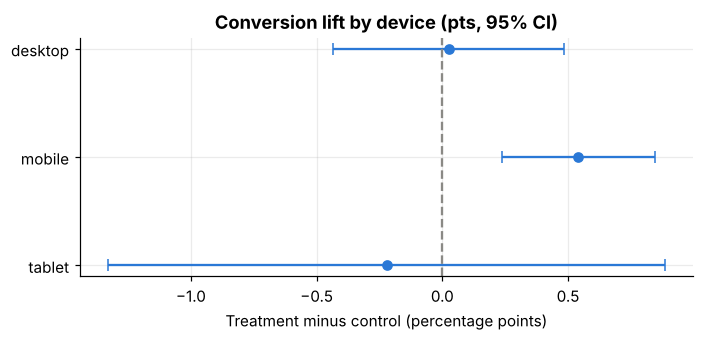

In [7]:
rows = []
for dim, seg in (("device", df.device), ("customer_type", np.where(df.is_returning == 1, "returning", "new"))):
    d = df.assign(seg=seg)
    for s in sorted(d.seg.unique()):
        a, b = d[(d.seg == s) & (d.variant == "treatment")], d[(d.seg == s) & (d.variant == "control")]
        xx = np.array([a.converted.sum(), b.converted.sum()]); nn = np.array([len(a), len(b)])
        pt_, pc_ = xx / nn; zz, pp = proportions_ztest(xx, nn)
        l, h = confint_proportions_2indep(xx[0], nn[0], xx[1], nn[1], method="newcombe", compare="diff")
        rows.append(dict(dimension=dim, segment=s, users=len(a)+len(b), control_pct=100*pc_, treatment_pct=100*pt_, diff_pts=100*(pt_-pc_),
                         ci_low=100*l, ci_high=100*h, rel_lift_pct=100*(pt_/pc_-1), p_raw=pp))
seg = pd.DataFrame(rows)
seg["p_holm"] = multipletests(seg.p_raw, method="holm")[1]
display(seg.round(3))

full = smf.logit("converted ~ C(variant) * C(device)", df).fit(disp=0)
red = smf.logit("converted ~ C(variant) + C(device)", df).fit(disp=0)
lr = 2*(full.llf - red.llf); p_int = stats.chi2.sf(lr, df=2)
print(f"Interaction test variant x device: LR chi2 = {lr:.2f}, df = 2, p = {p_int:.4f}")
M["segments"] = seg.round(4).to_dict(orient="records"); M["interaction_p_device"] = float(p_int)

dseg = seg[seg.dimension == "device"].iloc[::-1]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.errorbar(dseg.diff_pts, range(len(dseg)), xerr=[dseg.diff_pts-dseg.ci_low, dseg.ci_high-dseg.diff_pts], fmt="o", color=BLUE, capsize=4)
ax.axvline(0, color=GREY, ls="--"); ax.set_yticks(range(len(dseg))); ax.set_yticklabels(dseg.segment)
ax.set(title="Conversion lift by device (pts, 95% CI)", xlabel="Treatment minus control (percentage points)")
plt.tight_layout(); plt.savefig(ASSETS/"04_segment_forest.png", dpi=150, bbox_inches="tight"); plt.show()

## 7. Stability over time

A lift that decays across the test (novelty effect) would not hold after launch. We look at the daily lift and compare week 1 with week 2.

Week 1: relative lift +8.5%  (n = 61,991)
Week 2: relative lift +4.3%  (n = 62,009)


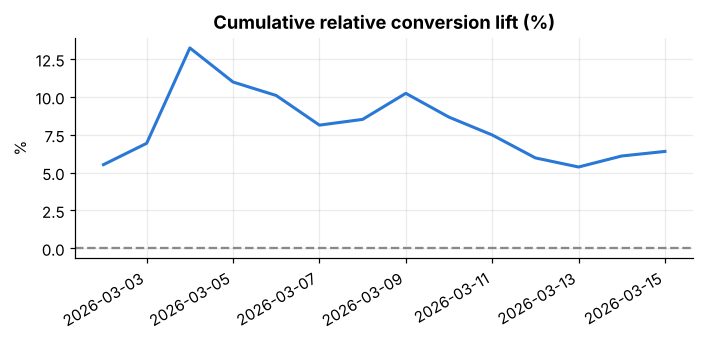

Does the lift differ between weeks? LR test p = 0.411


In [8]:
daily = pd.read_csv(PROC/"exp_daily.csv", parse_dates=["assigned_date"])
pv = daily.pivot(index="assigned_date", columns="variant", values=["cum_orders", "cum_users"])
cum_lift = (pv[("cum_orders", "treatment")]/pv[("cum_users", "treatment")]) / (pv[("cum_orders", "control")]/pv[("cum_users", "control")]) - 1
d2 = df.assign(week=np.where(df.assigned_date < df.assigned_date.min() + pd.Timedelta(days=7), "Week 1", "Week 2"))
wk = {}
for wlab, g in d2.groupby("week"):
    a, b = g[g.variant == "treatment"].converted, g[g.variant == "control"].converted
    wk[wlab] = (a.mean()/b.mean() - 1) * 100
    print(f"{wlab}: relative lift {wk[wlab]:+.1f}%  (n = {len(g):,})")
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(cum_lift.index, 100*cum_lift, color=BLUE, lw=2); ax.axhline(0, color=GREY, ls="--")
ax.set(title="Cumulative relative conversion lift (%)", ylabel="%"); fig.autofmt_xdate()
plt.tight_layout(); plt.savefig(ASSETS/"05_cumulative_lift.png", dpi=150, bbox_inches="tight"); plt.show()
d2["tr"] = (d2.variant == "treatment").astype(int)
m_full = smf.logit("converted ~ tr * C(week)", d2).fit(disp=0); m_red = smf.logit("converted ~ tr + C(week)", d2).fit(disp=0)
p_week = stats.chi2.sf(2*(m_full.llf - m_red.llf), df=1)
print(f"Does the lift differ between weeks? LR test p = {p_week:.3f}")
M["stability"] = dict(week_diff_p=round(float(p_week), 3), week1_lift_pct=round(wk["Week 1"], 1), week2_lift_pct=round(wk["Week 2"], 1))

## 8. Business impact and decision

Annualised incremental revenue = RPV difference x annual visitors. Annual traffic of **3.0M unique visitors** is an assumption
(replace with the real figure). The conservative number uses the lower bound of the CUPED confidence interval.

In [9]:
ANNUAL_VISITORS = 3_000_000
point = diff_c * ANNUAL_VISITORS
lo_i, hi_i = (diff_c - 1.96*se_c) * ANNUAL_VISITORS, (diff_c + 1.96*se_c) * ANNUAL_VISITORS
print(f"Incremental annual revenue: ${point/1e3:,.0f}K (95% CI ${lo_i/1e3:,.0f}K to ${hi_i/1e3:,.0f}K)")
mob = seg[(seg.dimension == "device") & (seg.segment == "mobile")].iloc[0]
print(f"Mobile alone: {mob.diff_pts:+.2f} pts ({mob.rel_lift_pct:+.1f}% relative), Holm p = {mob.p_holm:.4f}")
M["impact"] = dict(annual_visitors=ANNUAL_VISITORS, annual_rev=round(float(point)), annual_rev_ci=[round(float(lo_i)), round(float(hi_i))])
decision = "SHIP" if (p_val < ALPHA and hi_r < margin and diff_c > 0) else "DO NOT SHIP"
print("Decision rule (primary significant, guardrail passed, RPV positive):", decision)
M["decision"] = decision
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    return o
(RESULTS/"ab_metrics.json").write_text(json.dumps(clean(M), indent=2)); print("saved results/ab_metrics.json")

Incremental annual revenue: $1,747K (95% CI $856K to $2,638K)
Mobile alone: +0.54 pts (+12.2% relative), Holm p = 0.0025
Decision rule (primary significant, guardrail passed, RPV positive): SHIP
saved results/ab_metrics.json


### Interpretation

* The primary result is statistically significant and the trust checks pass. The refund guardrail passes, but only narrowly (upper bound just under the margin) and the test is underpowered for small refund increases, so refunds should be monitored after launch. The point estimate (about +6%) is *below* the 8% relative lift the test was powered for,
  and the confidence interval is wide (roughly +1.5% to +11.5%), so the true lift could be modest.
* The effect is **concentrated on mobile**, which survives Holm correction; desktop and tablet are indistinguishable from zero. The formal `variant x device` interaction test is borderline
  (p about 0.05), so treat "mobile only" as a strong hypothesis to confirm, not a settled fact.
* CUPED gives only a modest variance reduction here: pre-period spend is only weakly correlated with the next two weeks' (mostly zero) revenue. It is cheap, but not a big lever on this metric.
* If the week 1 versus week 2 lift looks different, check the interaction p-value before calling it a novelty effect; small samples produce wobbly daily lifts.
* **Caveats:** two weeks may not cover a full purchase cycle; revenue figures assume constant traffic; the experiment cannot say *why* mobile responds more
  (a follow-up with session recordings or a mobile-only variant would).